In [1]:
%%capture
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
!pip install lime
from lime.lime_tabular import LimeTabularExplainer
from lime import submodular_pick
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from collections import defaultdict
from sklearn.metrics import accuracy_score
import shap
import warnings
warnings.filterwarnings('ignore')

# XAI Lab: LIME and SHAP

In [2]:
# Load data
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

display(X.head())

# Create training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the data
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Create DataFrame version with feature names for SHAP
X_test_df = pd.DataFrame(X_test_s, columns=X.columns.tolist())
feature_names = X.columns.tolist()

print(f"Training set: {X_train_s.shape}, Test set: {X_test_s.shape}")
print(f"Classes: {dict(zip(data.target_names, [sum(y_test==0), sum(y_test==1)]))}")

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Training set: (455, 30), Test set: (114, 30)
Classes: {'malignant': 43, 'benign': 71}


Complete the coding exercises below.

## LIME

- **Task (0.5 points):** Select a model (e.g. random forest, gradient boosting, neural network) to address the given task and fit it on the dataset.
- **Task (0.5 points):** Run LIME explainer for the trained model.
- **Task (1 point):** Run local explanations for 4 test samples of your choice from different classes.
- **Task (1 point):** Barplot of the top 5 most influential and top 5 least influential global features created by averaging the feature importances from 100 randomly chosen test samples. Looking at the bar plot of the least influential global features, do you think these features are genuinely uninformative for cancer diagnosis, or could the model be underutilising potentially relevant signals?
- **Task (1 point):** Plot a global overview of the most important features for the model's predictions for the same 100 randomly chosen test samples in the previous task using SP-LIME.
- **Task (1 point):** Create a heatmap where each row is one of the 100 samples and each column is a feature, with cell colour showing the LIME importance weight. This lets you see at a glance which features drive predictions consistently across samples and which vary. Does the heatmap reveal consistent or varying importance of features across samples?

### Coding Tasks

**Task (0.5 points):** Select a model (e.g. random forest, gradient boosting, neural network) to address the given task and fit it on the dataset.

In [3]:
from sklearn.neural_network import MLPClassifier
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

# Model parameters
mlp_model = MLPClassifier(
    hidden_layer_sizes=(30),
    activation='relu',
    solver='adam',
    random_state=42
)

train_loss = []
test_loss = []

# Definition classes
classes = np.unique(y_train)

for epoch in range(150):
    mlp_model.partial_fit(X_train_s, y_train, classes=classes)

    # Train loss
    train_loss.append(mlp_model.loss_)

    # Test loss
    y_test_proba = mlp_model.predict_proba(X_test_s)
    test_loss.append(log_loss(y_test, y_test_proba))

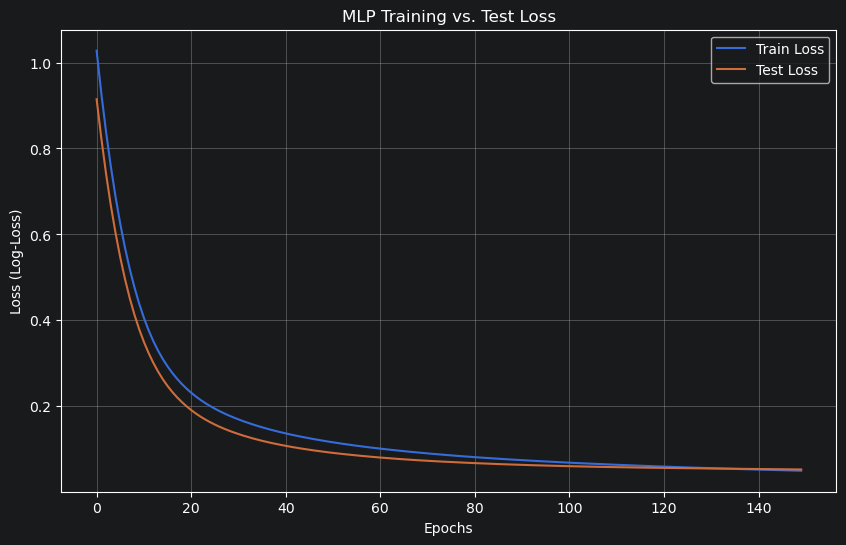

In [4]:
# Plot
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Train Loss')
plt.plot(test_loss, label='Test Loss')
plt.title('MLP Training vs. Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss (Log-Loss)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# Plot measures confusion matrix, accuracy, precision, recall, f1-score
from sklearn.metrics import confusion_matrix, classification_report
y_pred = mlp_model.predict(X_test_s)
print("Confusion Matrix (Test set):")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report (Test set):")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Confusion Matrix (Test set):
[[42  1]
 [ 0 71]]

Classification Report (Test set):
              precision    recall  f1-score   support

   malignant       1.00      0.98      0.99        43
      benign       0.99      1.00      0.99        71

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



**Task (0.5 points):** Run LIME explainer for the trained model.

In [6]:
# Create LIME explainer
explainer = LimeTabularExplainer(X_train_s, feature_names=feature_names, class_names=data.target_names, discretize_continuous=True)

**Task (1 point):** Run local explanations for 4 test samples of your choice from different classes.

In [7]:
# Select 4 test samples from different classes
sample_indices = [0, 1, 2, 3]  # Adjust indices as needed
for idx in sample_indices:
    exp = explainer.explain_instance(X_train_s[idx], mlp_model.predict_proba, num_features=10)
    print(f"Explanation for test sample index {idx}:")
    print(exp.as_list())

Explanation for test sample index 0:
[('worst concavity > 0.54', -0.18506474440065923), ('worst smoothness > 0.63', -0.18314200610139433), ('worst concave points > 0.72', -0.1579108200807073), ('compactness error > 0.36', 0.14521993623560353), ('mean fractal dimension > 0.46', 0.13221969710094877), ('mean perimeter <= -0.69', 0.10909177620835069), ('fractal dimension error > 0.25', 0.10656285587409972), ('worst radius <= -0.66', 0.10071191011404214), ('worst area <= -0.64', 0.1002458044024859), ('area error <= -0.46', 0.07599219549700985)]
Explanation for test sample index 1:
[('radius error > 0.23', -0.24535954292100118), ('worst concavity > 0.54', -0.19785730340664237), ('area error > 0.08', -0.18616783880009338), ('worst texture > 0.69', -0.168054045282966), ('worst smoothness > 0.63', -0.16303112516680224), ('worst area > 0.27', -0.15761682271924665), ('worst concave points > 0.72', -0.15704596119189942), ('worst radius > 0.45', -0.15093327790519245), ('mean texture > 0.56', -0.150

In [8]:
# Visualize explanations for the 4 samples
from IPython.display import display, HTML
for idx in sample_indices:
    exp = explainer.explain_instance(X_train_s[idx], mlp_model.predict_proba, num_features=10)
    print(f"\nExplanation for train sample index {idx}:")
    display(HTML(exp.as_html()))


Explanation for train sample index 0:



Explanation for train sample index 1:



Explanation for train sample index 2:



Explanation for train sample index 3:


**Task (1 point):** Barplot of the top 5 most influential and top 5 least influential global features created by averaging the feature importances from 100 randomly chosen test samples. Looking at the bar plot of the least influential global features, do you think these features are genuinely uninformative for cancer diagnosis, or could the model be underutilising potentially relevant signals?

In [9]:
# Get feature importance for num_samples random test samples
num_samples = 100
total_test_samples = X_train_s.shape[0]
chosen_indices = np.random.choice(range(total_test_samples), num_samples, replace=False)

feature_importance = defaultdict(list)
for idx in chosen_indices:
    exp = explainer.explain_instance(X_train_s[idx], mlp_model.predict_proba, num_features=len(feature_names))
    for feature, importance in exp.local_exp[1]:
        feature_importance[feature].append(abs(importance))

# Average importance across samples
avg_importance = {feature: np.mean(importances) for feature, importances in feature_importance.items()}

# convert to DataFrame for plotting
importance_df = pd.DataFrame(avg_importance.items(), columns=['Feature', 'Average Importance'])
importance_df = importance_df.sort_values(by='Average Importance', ascending=False)
importance_df['Feature'] = importance_df['Feature'].apply(lambda x: feature_names[x])
importance_df

,Feature,Average Importance
4,radius error,0.114552
2,worst texture,0.106875
1,worst concavity,0.101806
3,worst smoothness,0.101037
7,area error,0.092744
8,mean texture,0.090139
0,worst concave points,0.088259
22,worst radius,0.086298
16,worst area,0.080138
27,mean perimeter,0.073342


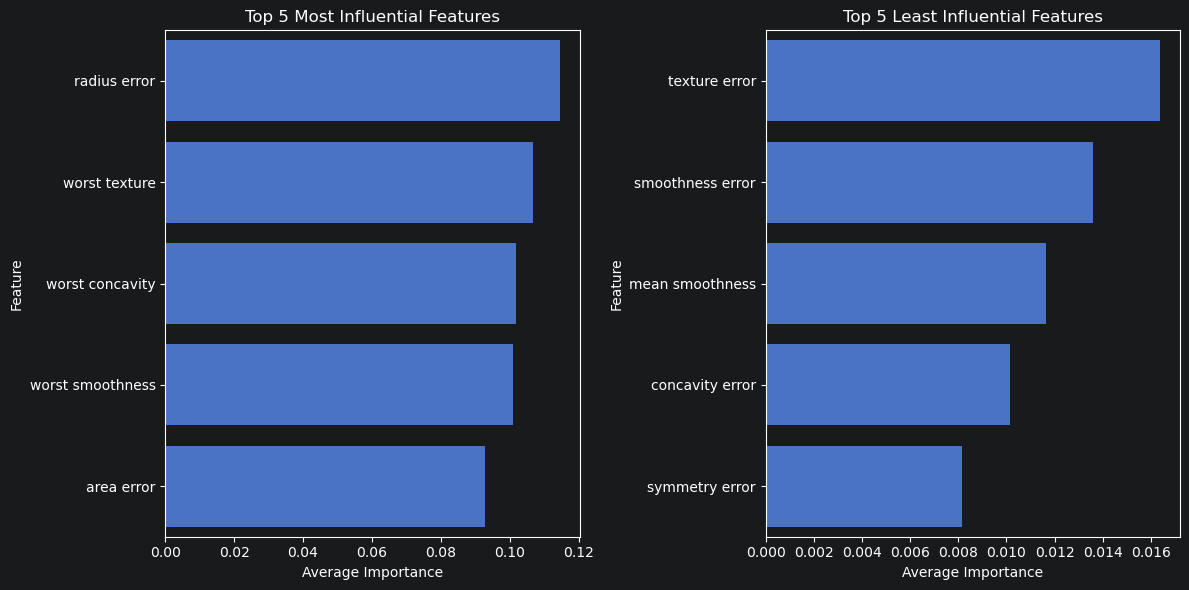

In [10]:
# Bar plot next to each other of top 5 most influential and top 5 least influential features
plt.figure(figsize=(12, 6))
# Top 5 most influential features
plt.subplot(1, 2, 1)
sns.barplot(x='Average Importance', y='Feature', data=importance_df.head(5))
plt.title('Top 5 Most Influential Features')
# Top 5 least influential features
plt.subplot(1, 2, 2)
sns.barplot(x='Average Importance', y='Feature', data=importance_df.tail(5))
plt.title('Top 5 Least Influential Features')
plt.tight_layout()
plt.show()

**Possible Explanation:**
- The top features such as radius error or area error are absolute likely to be this relevant. After a short research I found that healthy cells have a more regular shape and are smaller, in contrast to cancerous cells which have more irregular shapes.
- Since there are this many features I would guess that many features are correlated to some extent, therefore I would not say that the least influential features are genuinely unrelevant but rather already represented in the model by other correlated features.

**Task (1 point):** Plot a global overview of the most important features for the model's predictions for the same 100 randomly chosen test samples in the previous task using SP-LIME.


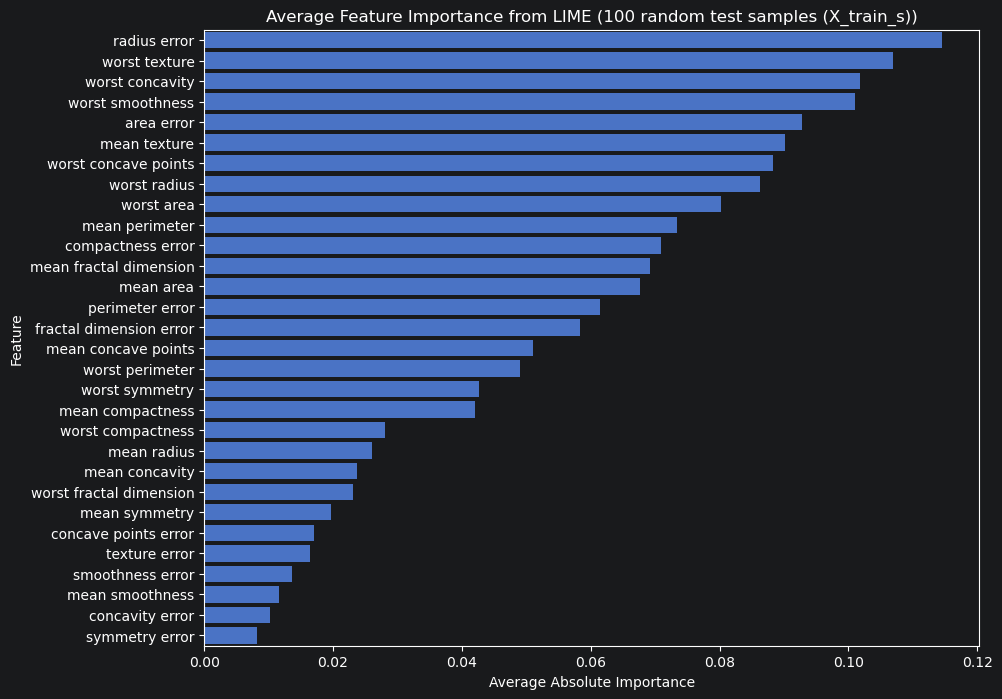

In [11]:
# Overall horizontal bar plot of all features sorted by importance
plt.figure(figsize=(10, 8))
sns.barplot(x='Average Importance', y='Feature', data=importance_df)
plt.title(f'Average Feature Importance from LIME ({num_samples} random test samples (X_train_s))')
plt.xlabel('Average Absolute Importance')
plt.ylabel('Feature')
plt.show()

**Task (1 point):** Create a heatmap where each row is one of the 100 samples and each column is a feature, with cell colour showing the LIME importance weight. This lets you see at a glance which features drive predictions consistently across samples and which vary. Does the heatmap reveal consistent or varying importance of features across samples?

In [12]:
# save feature importance for each sample in a DataFrame
heatmap_data = pd.DataFrame(index=chosen_indices, columns=feature_names)
for idx in chosen_indices:
    exp = explainer.explain_instance(X_train_s[idx], mlp_model.predict_proba, num_features=len(feature_names))
    for feature, importance in exp.local_exp[1]:
        heatmap_data.loc[idx, feature_names[feature]] = abs(importance)

# standardize the heatmap data for better visualization
heatmap_data = heatmap_data.astype(float)
heatmap_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())

# create dataframe of chosen_indices
heatmap_data_chosen = heatmap_data.copy()
heatmap_data_chosen['Sample Index'] = heatmap_data_chosen.index
heatmap_data_chosen = heatmap_data_chosen.set_index('Sample Index')

heatmap_data_chosen

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
Sample Index,,,,,,,,,,,,,,,,,,,,,
453,0.084070,0.170816,0.077908,0.043744,0.279626,0.140798,0.093684,0.000000,0.070691,0.011062,...,0.117059,1.000000,0.043059,0.008027,0.816437,0.579397,0.789705,0.972587,0.744154,0.612903
209,0.168498,0.214706,0.343765,0.237526,0.493439,0.285316,0.024868,0.365824,0.090761,0.872922,...,0.708142,0.722610,0.431190,0.538522,0.822556,0.395828,0.600217,0.832162,0.600826,0.432537
124,0.265820,0.779763,0.467800,0.351763,0.435344,0.623999,0.036051,0.351800,0.553751,0.617831,...,0.028238,0.171445,0.035932,0.079430,0.766128,0.718021,0.347445,0.152709,0.573222,0.283957
296,0.243960,0.156253,0.686961,0.373028,0.171755,0.058150,0.608181,0.446547,0.125110,0.071379,...,0.608095,0.079760,0.558601,0.512155,0.000000,0.185404,0.611357,0.348453,0.289969,0.021951
134,0.178413,0.100905,0.114859,0.002378,0.606846,0.337540,0.194340,0.278377,0.846946,0.578306,...,0.137688,0.899059,0.025916,0.151833,0.917769,0.087638,0.401504,0.490907,0.466575,0.283844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
404,0.422337,0.318792,0.946587,0.882605,0.381420,0.752418,0.668801,1.000000,0.377024,0.131957,...,0.873718,0.007213,0.811161,0.832754,0.085806,0.662392,0.894621,0.864772,0.796864,0.567239
274,0.386884,0.922839,0.742788,0.480950,0.091592,0.223959,0.024034,0.031633,0.533065,0.061895,...,0.657203,0.849221,0.580262,0.480212,0.169056,0.219129,0.069989,0.345851,0.729438,0.135523
258,0.550361,0.810684,0.828483,0.897182,0.090252,0.033341,0.529581,0.723057,0.064075,0.648222,...,0.919545,0.026919,0.753798,0.862531,0.200571,0.846705,0.864378,0.832740,0.837030,0.006393


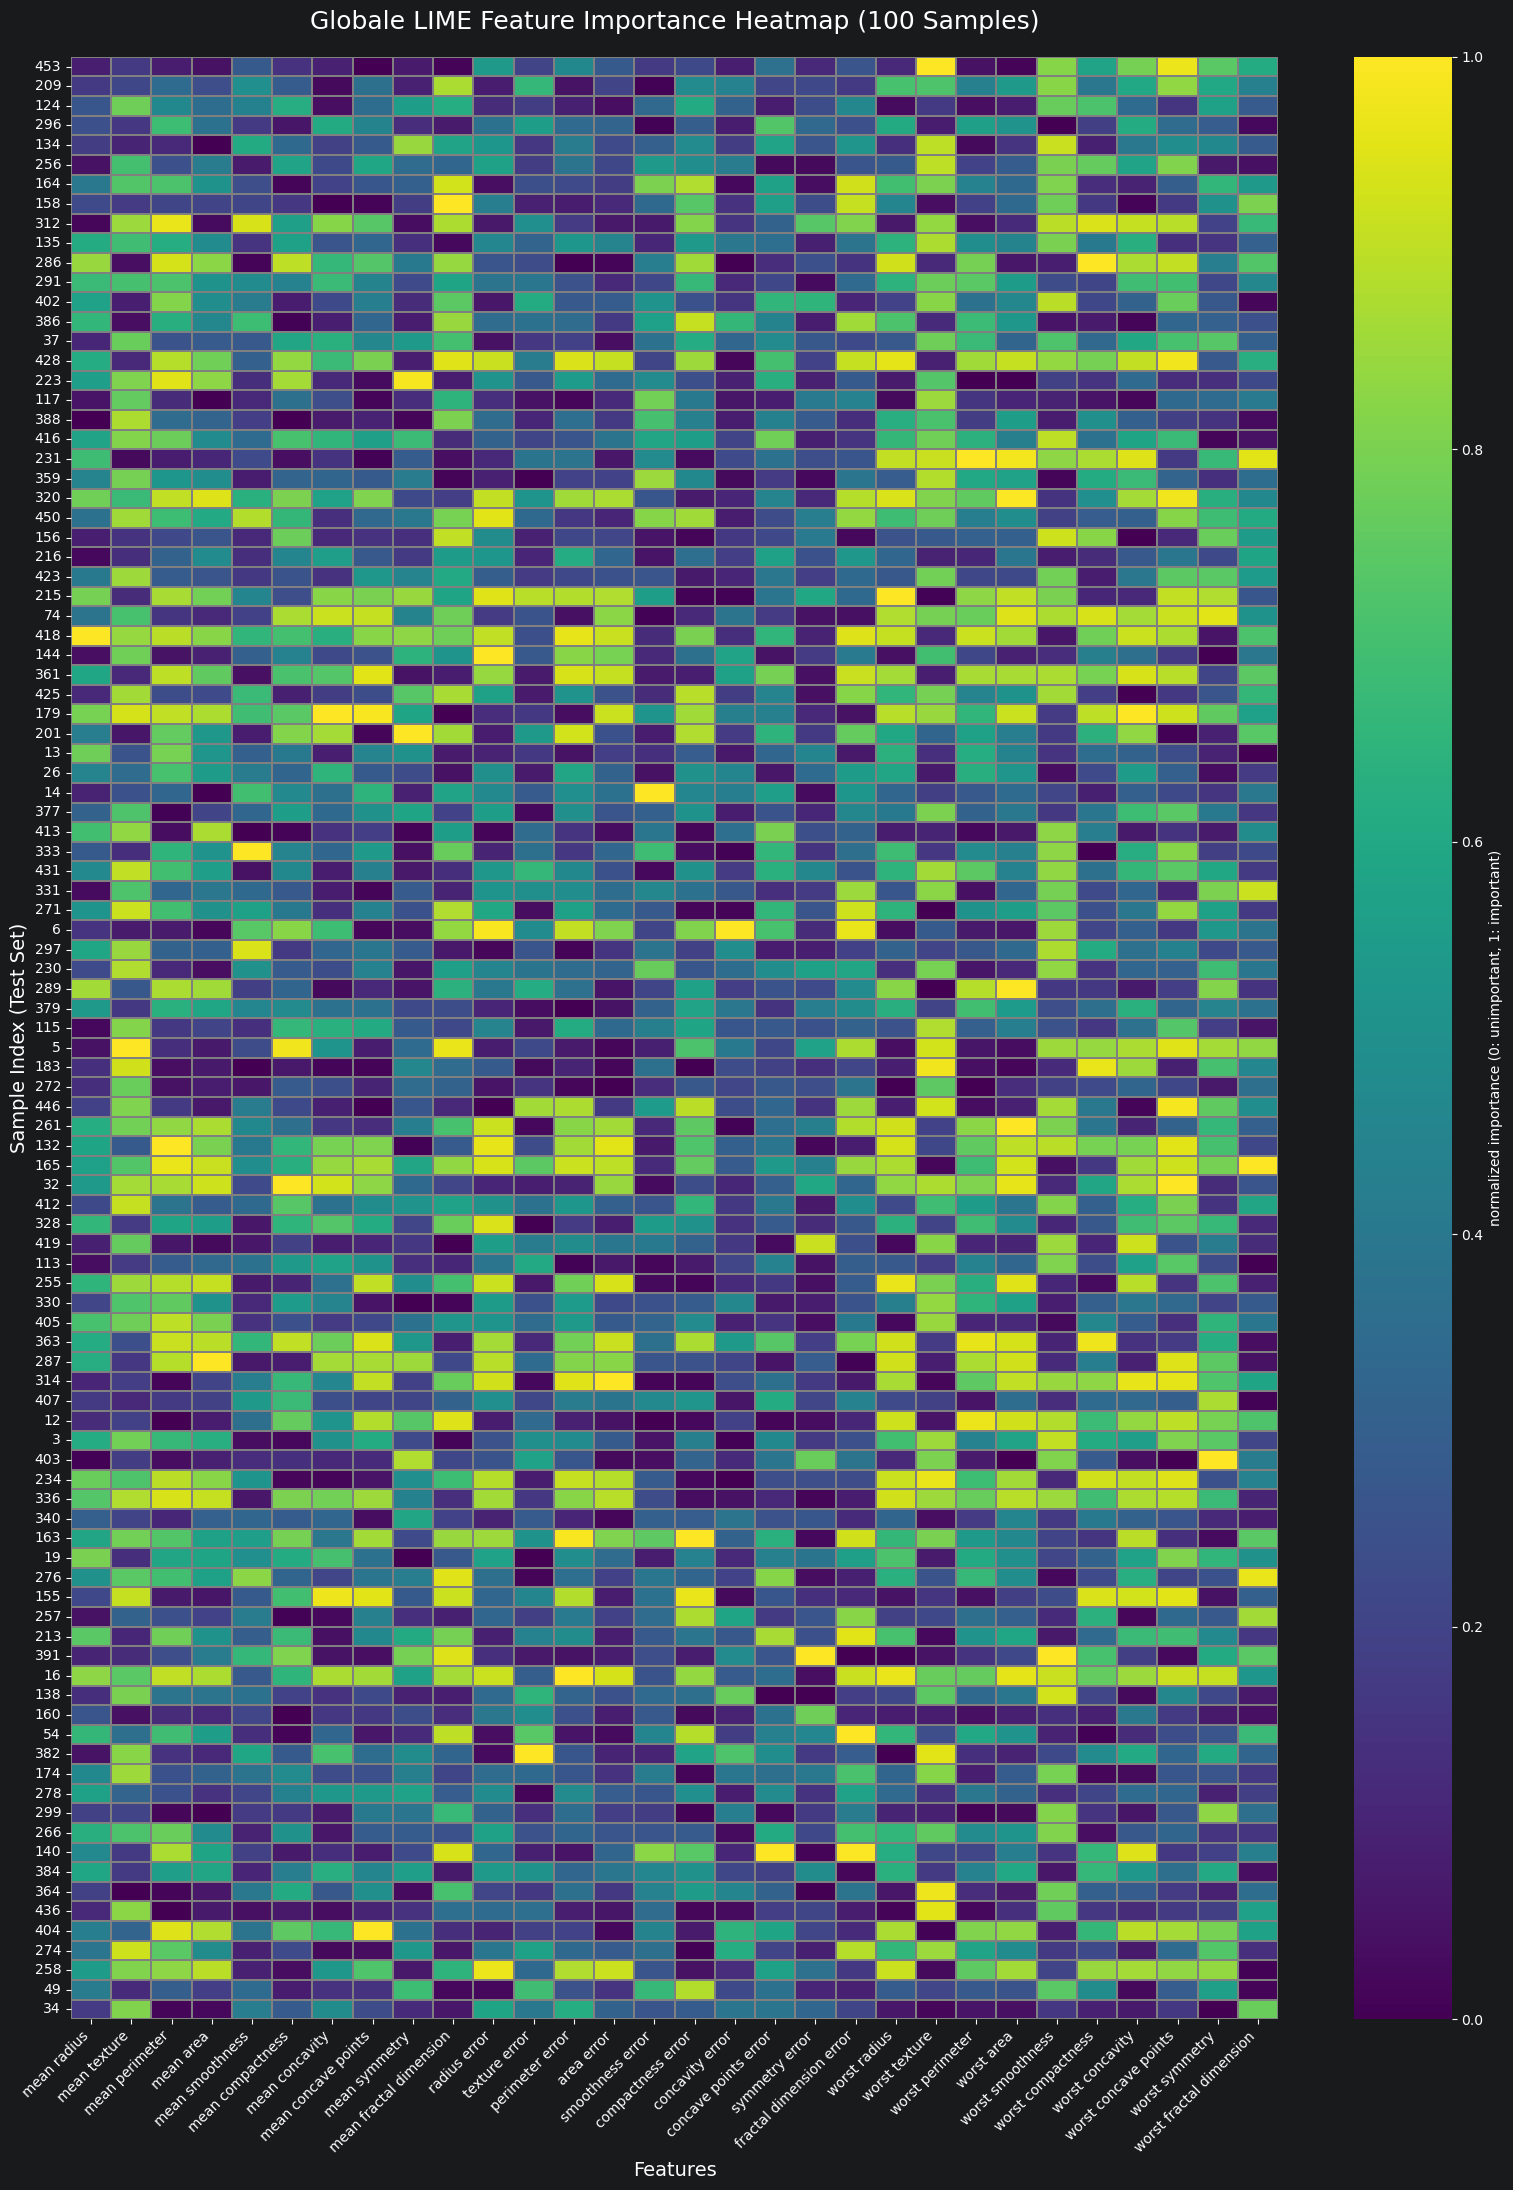

In [13]:
# Heatmap

plt.figure(figsize=(16, 22))

sns.heatmap(heatmap_data_chosen,
            cmap='viridis',
            cbar_kws={'label': 'normalized importance (0: unimportant, 1: important)'},
            linewidths=0.01, # Hauchdünne Linien für die Trennung
            linecolor='gray')

plt.title('Globale LIME Feature Importance Heatmap (100 Samples)', fontsize=18, pad=20)
plt.xlabel('Features', fontsize=14)
plt.ylabel('Sample Index (Test Set)', fontsize=14)

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Possible Explanation:**
- To my surprise there is no clear pattern visible. I guess this is mostly due to the reason that we have a lot of features.
- If you take a closer look you can see that features such as 'mean texture' or 'worst texture' seem to on a lot of samples a relativ high importance.

## SHAP

- **Task (1 point):** Apply SHAP explainer on the trained model. Plot a force plot for the same 4 test samples you had selected for LIME.
- **Task (1 point):** Visualize how each feature contributes to the predicted probability of the selected 4 test samples using the waterfall plot. Compare the results to those from LIME for the same samples. What do you observe?
- **Task (0.5 points):** Plot a summary plot (global overview) of how each feature affects the model's prediction for the complete test set.
- **Task (1 point):** Create a SHAP explainer for the same 100 random test samples you used in the LIME task. Plot a global overview of how each feature affects the model prediction. How does this compare to the global explanations from SP-LIME?
- **Task (0.5 points):** Make a data frame that contains the top 5 most influential features for all test samples.
- **Task (1 point):** Plot a dependence plot for two of the most important features: `worst concave points` and `worst area`.

**Task (1 point):** Apply SHAP explainer on the trained model. Plot a force plot for the same 4 test samples you had selected for LIME.

In [14]:
# Create SHAP explainer

background = shap.sample(X_train_s, 100)
explainer_shap = shap.KernelExplainer(mlp_model.predict_proba, background)

# sample_indices = [24, 49, 45, 85] # -> same as before

X_samples = X_train_s[sample_indices]
shap_values = explainer_shap.shap_values(X_samples)

# Plot
shap.initjs()

for i, idx in enumerate(sample_indices):
    print(f"\nSHAP Force Plot for Test Sample Index {idx}:")
    current_shap_values = shap_values[i, :, 1]
    expected_value = explainer_shap.expected_value[1]
    display(shap.force_plot(
        expected_value,
        current_shap_values,
        X_samples[i],
        feature_names=feature_names
    ))

  0%|          | 0/4 [00:00<?, ?it/s]


SHAP Force Plot for Test Sample Index 0:



SHAP Force Plot for Test Sample Index 1:



SHAP Force Plot for Test Sample Index 2:



SHAP Force Plot for Test Sample Index 3:


**Task (1 point):** Visualize how each feature contributes to the predicted probability of the selected 4 test samples using the waterfall plot. Compare the results to those from LIME for the same samples. What do you observe?


SHAP Waterfall Plot for Test Sample Index 0:


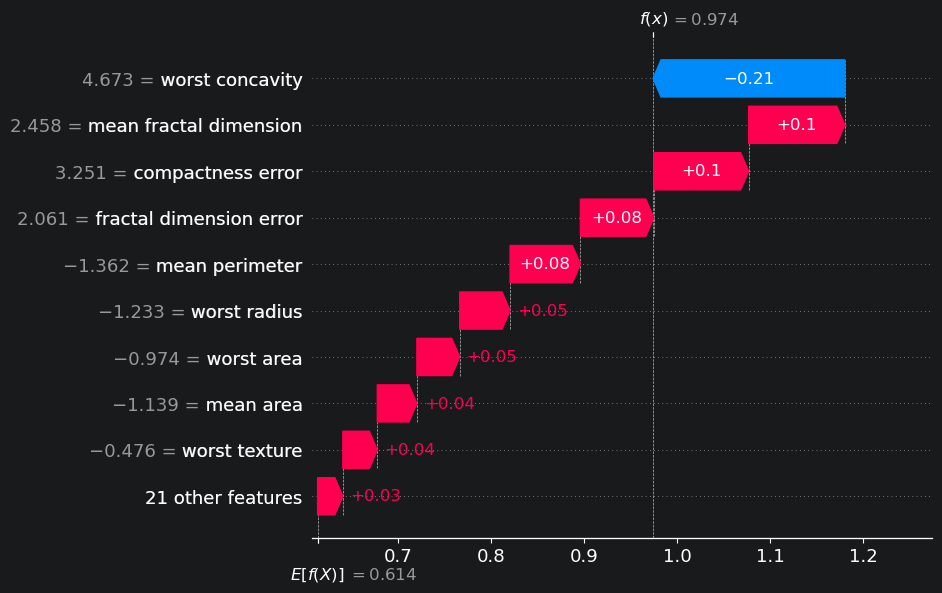


SHAP Waterfall Plot for Test Sample Index 1:


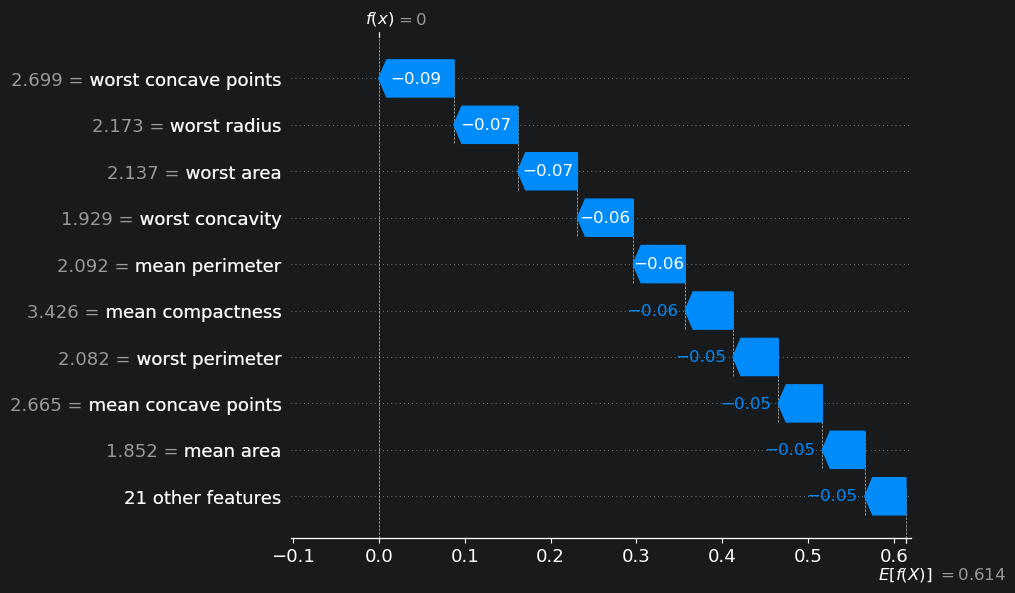


SHAP Waterfall Plot for Test Sample Index 2:


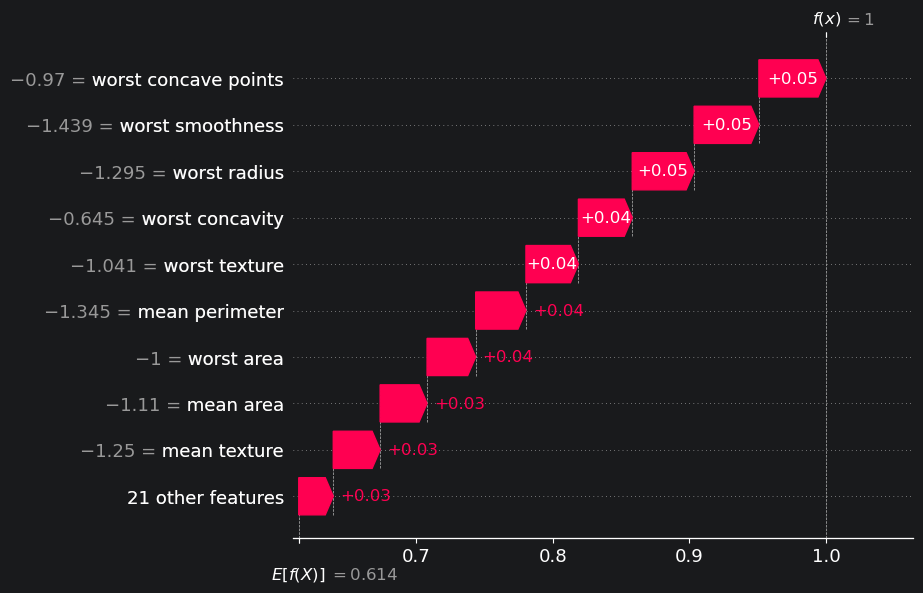


SHAP Waterfall Plot for Test Sample Index 3:


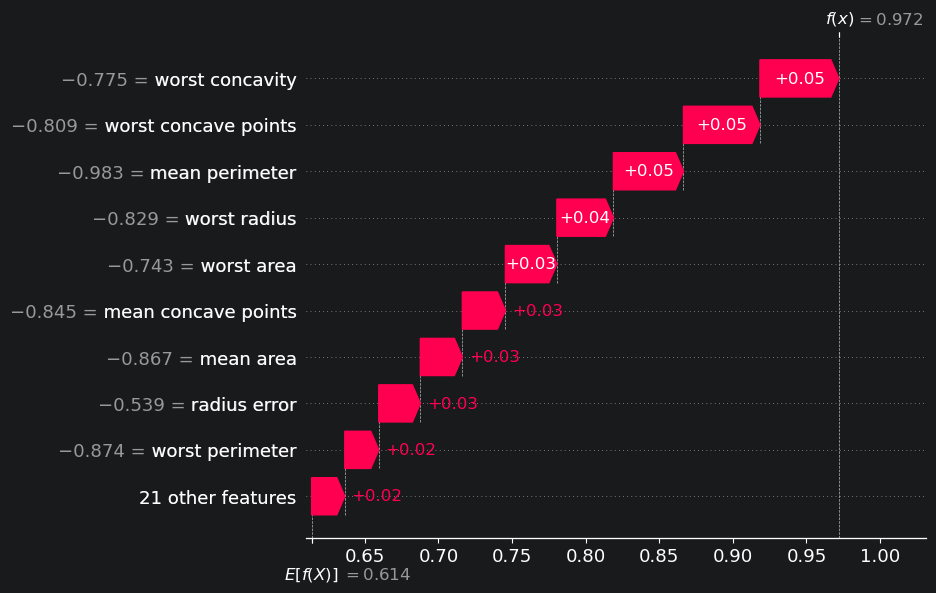

In [15]:
for i, idx in enumerate(sample_indices):
    print(f"\nSHAP Waterfall Plot for Test Sample Index {idx}:")
    current_shap_values = shap_values[i, :, 1]
    expected_value = explainer_shap.expected_value[1]
    shap.plots.waterfall(shap.Explanation(values=current_shap_values, base_values=expected_value, data=X_samples[i], feature_names=feature_names))

**Task (0.5 points):** Plot a summary plot of how each feature affects the model's prediction for the complete test set.

In [16]:
# Get SHAP values for the complete test set
shap_values_full = explainer_shap.shap_values(X_train_s)
shap_values_full

  0%|          | 0/455 [00:00<?, ?it/s]

array([[[-0.02708765,  0.02708765],
        [ 0.        ,  0.        ],
        [-0.06860996,  0.06860996],
        ...,
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ]],

       [[ 0.        ,  0.        ],
        [ 0.06106906, -0.06106906],
        [ 0.05329206, -0.05329206],
        ...,
        [ 0.0856267 , -0.0856267 ],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ]],

       [[ 0.        ,  0.        ],
        [-0.04113573,  0.04113573],
        [-0.04115677,  0.04115677],
        ...,
        [-0.04185252,  0.04185252],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ]],

       ...,

       [[ 0.        ,  0.        ],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ],
        ...,
        [-0.05330512,  0.05330512],
        [-0.0262889 ,  0.0262889 ],
        [ 0.        ,  0.        ]],

       [[ 0.        ,  0.        ],
        [ 0.        ,  0.  

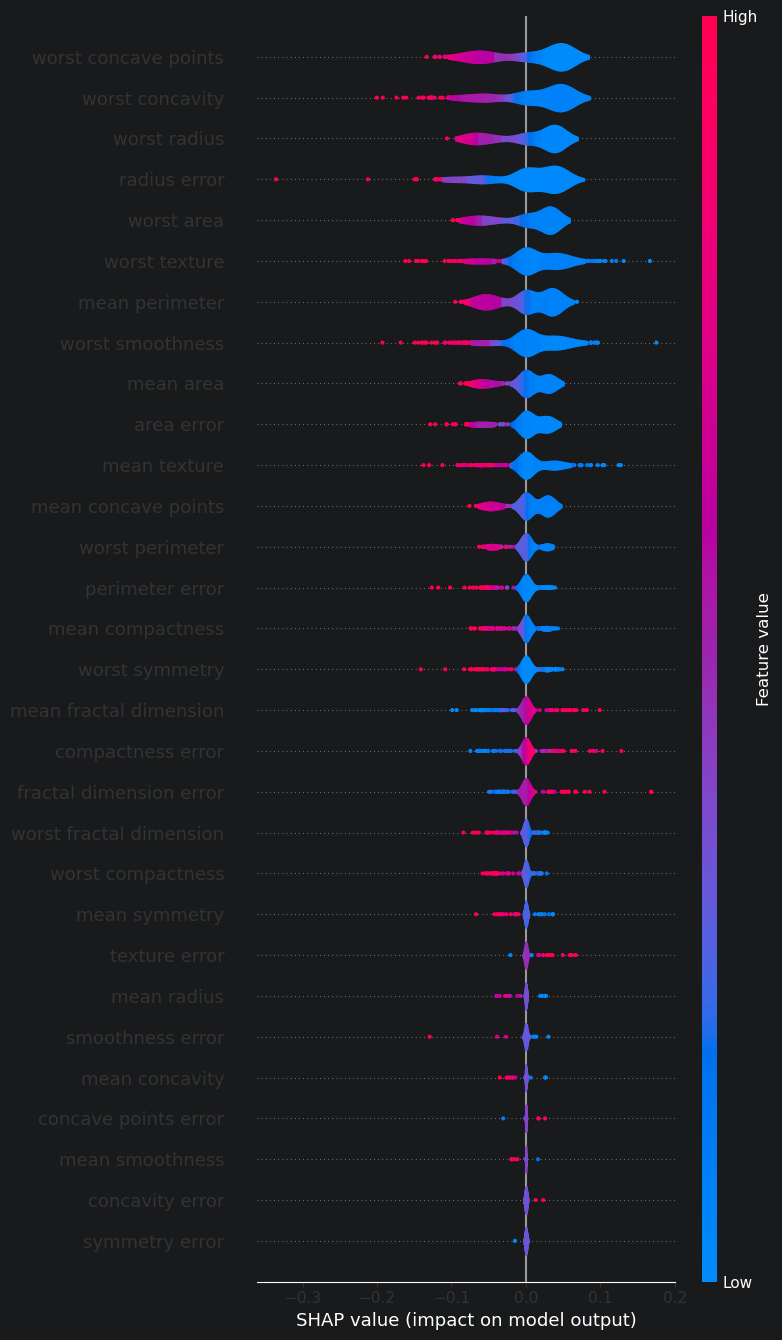

In [17]:
# Summary plot for the complete test set
shap.summary_plot(shap_values_full[:, :, 1], X_train_s, feature_names=feature_names, plot_type='violin', max_display=30)

**Task (1 point):** Create a SHAP explainer for the same 100 random test samples you used in the LIME task. Plot a global overview of how each feature affects the model prediction. How does this compare to the global explanations from SP-LIME?

In [18]:
# Get SHAP values for the 100 random test samples
shap_values_samples = explainer_shap.shap_values(X_train_s[chosen_indices])

  0%|          | 0/100 [00:00<?, ?it/s]

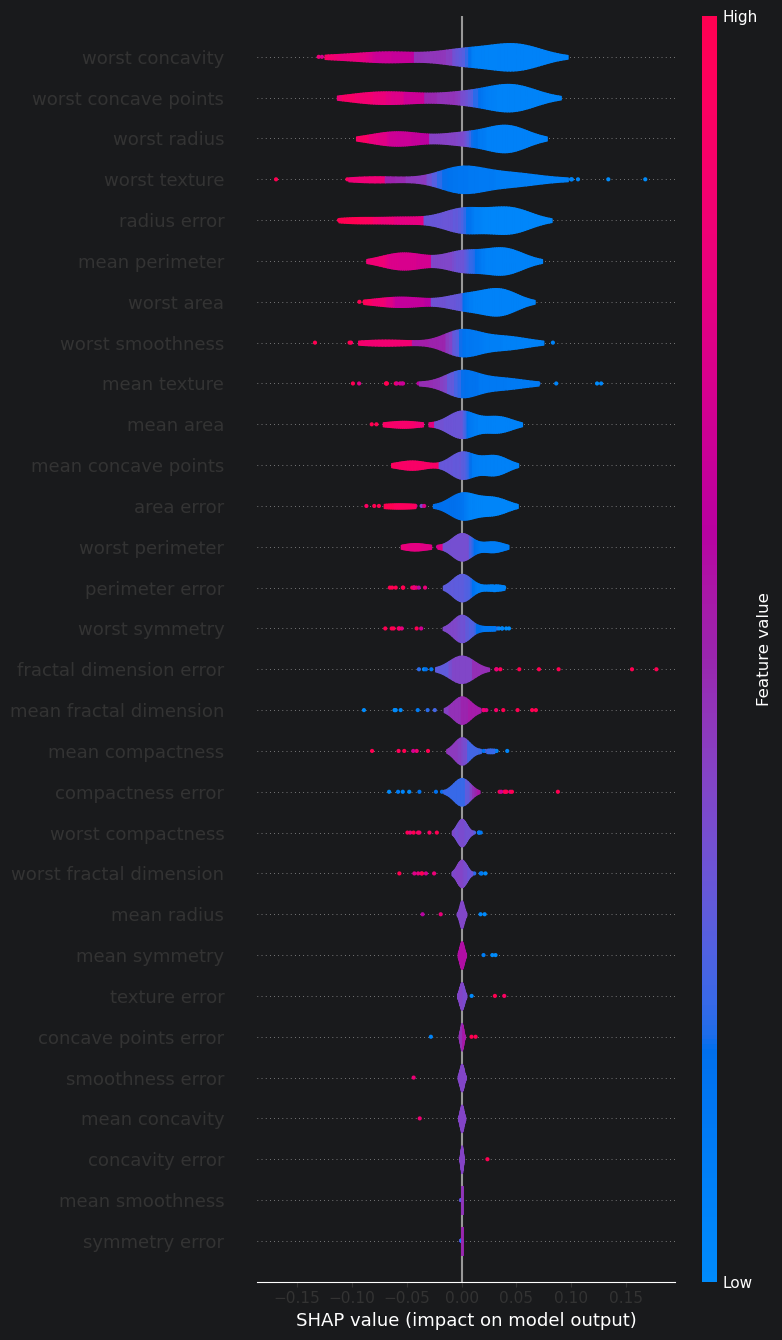

In [19]:
# Summary plot for the 100 random test samples
shap.summary_plot(shap_values_samples[:, :, 1], X_train_s[chosen_indices], feature_names=feature_names, plot_type='violin', max_display=30)

**Possible Explanation:**
- The features are overall in a different order. But I notice the features wich have a bigger impact during LIME tend to also have a bigger impact with SHAP. The same applies to the features with less impact. Overall you could say, the order is not exactly the same but more important features are most likely in the same region of the tierlist and vice versa.

**Task (0.5 points):** Make a data frame that contains the top 5 most influential features for all test samples.

In [20]:
# Dataframe of most influential features with SHAP-Score
mean_shap_values = np.abs(shap_values_full[:, :, 1]).mean(axis=0)
shap_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP_Score': mean_shap_values
})
shap_df = shap_df.sort_values(by='SHAP_Score', ascending=False).head(5)
shap_df

,Feature,SHAP_Score
27,worst concave points,0.047624
26,worst concavity,0.044852
20,worst radius,0.039357
10,radius error,0.036592
23,worst area,0.034174


**Task (1 point):** Plot a dependence plot for two of the most important features: `worst concave points` and `worst area`.

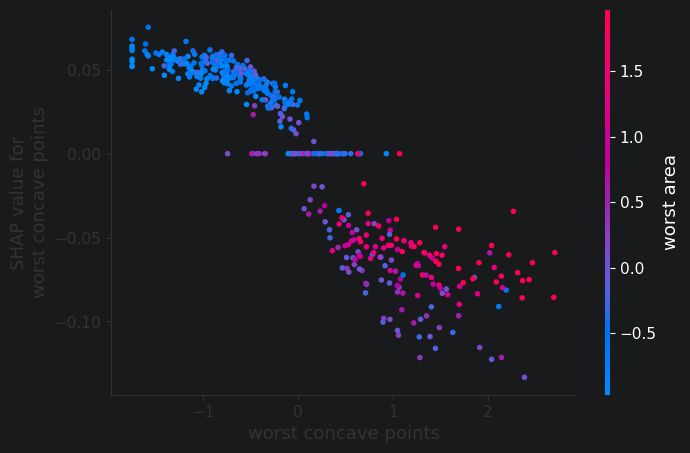

In [21]:
# Shap dependence plot for 'worst concave points' and 'worst area'
shap.dependence_plot(
    "worst concave points",
    shap_values_full[:, :, 1],
    X_train_s,
    feature_names=feature_names,
    interaction_index="worst area"
)